In [1]:
print("Hello vivek! Everything looks fine.")

Hello vivek! Everything looks fine.


In [2]:
import pandas as pd

file_path = '../data/IMDB Dataset.csv'

df = pd.read_csv(file_path)
print('Dataset loaded successfully into a pandas Dataframe!') 

Dataset loaded successfully into a pandas Dataframe!


In [3]:
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [4]:
df.shape

(50000, 2)

In [5]:
df.isnull().sum()

review       0
sentiment    0
dtype: int64

In [6]:
df['sentiment'].value_counts()

sentiment
positive    25000
negative    25000
Name: count, dtype: int64

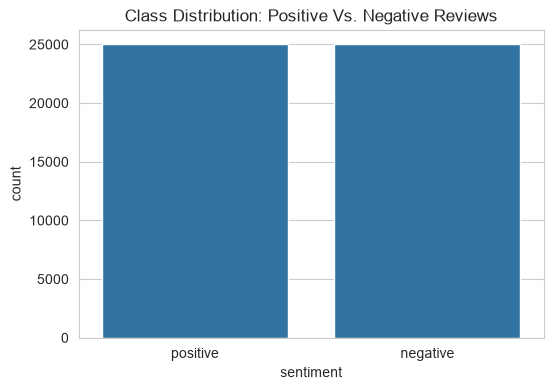

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')

plt.figure(figsize=(6, 4))
sns.countplot(x='sentiment', data=df)

plt.title('Class Distribution: Positive Vs. Negative Reviews')

plt.show()

In [8]:
def to_lowercase(text):
    return text.lower()

example_text = "This is A GREat MOvie! I Really enjoYED it."
cleaned_text = to_lowercase(example_text)

print("Original text:- " + example_text)
print("Cleaned text:- " + cleaned_text)    

Original text:- This is A GREat MOvie! I Really enjoYED it.
Cleaned text:- this is a great movie! i really enjoyed it.


In [9]:
df['review'] = df['review'].apply(to_lowercase)

print("DataFrame after applying the lowercase function:")
df.head()

DataFrame after applying the lowercase function:


,review,sentiment
0,one of the other reviewers has mentioned that ...,positive
1,a wonderful little production. <br /><br />the...,positive
2,i thought this was a wonderful way to spend ti...,positive
3,basically there's a family where a little boy ...,negative
4,"petter mattei's ""love in the time of money"" is...",positive


In [10]:
import re

def remove_html_tags(text):
    pattern = re.compile('<.*?>')
    
    return pattern.sub("", text)

example_text_with_html = "this was an <i>amazing</i> movie. i loved it! <br /><br />totally <b>worth</b> watching."
cleaned_text = remove_html_tags(example_text_with_html)

print("Original Text with HTML:  ", example_text_with_html)
print("Text after HTML removal:", cleaned_text)

Original Text with HTML:   this was an <i>amazing</i> movie. i loved it! <br /><br />totally <b>worth</b> watching.
Text after HTML removal: this was an amazing movie. i loved it! totally worth watching.


In [11]:
df['review'] = df['review'].apply(remove_html_tags)

print("DataFrame after removing HTML tags: ")
df.head()

DataFrame after removing HTML tags: 


,review,sentiment
0,one of the other reviewers has mentioned that ...,positive
1,a wonderful little production. the filming tec...,positive
2,i thought this was a wonderful way to spend ti...,positive
3,basically there's a family where a little boy ...,negative
4,"petter mattei's ""love in the time of money"" is...",positive


In [12]:
import re

def remove_punctuation(text):
    return re.sub(r'[^a-z0-9\s]', ' ', text).strip()

example_text_with_punc = "wow... this movie was *amazing*! (10/10). i'd say it's a 'must-see'."
cleaned_text = remove_punctuation(example_text_with_punc)

print("Original Text with Punctuation: ", example_text_with_punc)
print("Text after Punctuation Removal:", cleaned_text)

Original Text with Punctuation:  wow... this movie was *amazing*! (10/10). i'd say it's a 'must-see'.
Text after Punctuation Removal: wow    this movie was  amazing    10 10   i d say it s a  must see


In [13]:
df['review'] = df['review'].apply(remove_punctuation)

print("DataFrame after removing punctuation:")
df.head()

DataFrame after removing punctuation:


,review,sentiment
0,one of the other reviewers has mentioned that ...,positive
1,a wonderful little production the filming tec...,positive
2,i thought this was a wonderful way to spend ti...,positive
3,basically there s a family where a little boy ...,negative
4,petter mattei s love in the time of money is...,positive


In [14]:
import nltk

nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /Users/vivek/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [15]:
from nltk.corpus import stopwords

english_stopwords_list = stopwords.words('english')
print("--- First 10 Stopwords from NLTK List ---")
print(english_stopwords_list[:10])
print("\n" + "="*50 + "\n")

stop_words_set = set(english_stopwords_list)
print(f"We have successfully loaded {len(stop_words_set)} English stopwords into a highly efficient set.")

--- First 10 Stopwords from NLTK List ---
['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an']


We have successfully loaded 198 English stopwords into a highly efficient set.


In [16]:
def tokenize_and_remove_stopwords(text):

    tokens = text.split()

    cleaned_tokens = [token for token in tokens if token not in stop_words_set]

    return cleaned_tokens

example_sentence = "this movie is just a brilliant and beautiful production"
cleaned_tokens_list = tokenize_and_remove_stopwords(example_sentence)

print("Original Sentence:", example_sentence)
print("Tokens after Stopword Removal:", cleaned_tokens_list)

Original Sentence: this movie is just a brilliant and beautiful production
Tokens after Stopword Removal: ['movie', 'brilliant', 'beautiful', 'production']


In [17]:
df['review'] = df['review'].apply(tokenize_and_remove_stopwords)

print("DataFrame after tokenization and stopword removal:")
df.head()

DataFrame after tokenization and stopword removal:


,review,sentiment
0,"[one, reviewers, mentioned, watching, 1, oz, e...",positive
1,"[wonderful, little, production, filming, techn...",positive
2,"[thought, wonderful, way, spend, time, hot, su...",positive
3,"[basically, family, little, boy, jake, thinks,...",negative
4,"[petter, mattei, love, time, money, visually, ...",positive


In [18]:
import nltk

nltk.download('wordnet')

[nltk_data] Downloading package wordnet to /Users/vivek/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [19]:
from nltk.stem import WordNetLemmatizer

lemmatizer = WordNetLemmatizer()

print(f"The lemma for 'movies' is: {lemmatizer.lemmatize('movies')}")
print(f"The lemma for 'running' is: {lemmatizer.lemmatize('running')}")
print(f"The lemma for 'running' is: {lemmatizer.lemmatize('running', pos='v')}")

The lemma for 'movies' is: movie
The lemma for 'running' is: running
The lemma for 'running' is: run


In [20]:
def lemmatize_tokens(tokens):

    lemmatized_tokens = [lemmatizer.lemmatize(token) for token in tokens]

    return lemmatized_tokens

example_tokens = ['movies', 'are', 'amazing', 'characters', 'were', 'running', 'studies']
lemmatized_example = lemmatize_tokens(example_tokens)

print("Original Tokens:", example_tokens)
print("Lemmatized Tokens:", lemmatized_example)

Original Tokens: ['movies', 'are', 'amazing', 'characters', 'were', 'running', 'studies']
Lemmatized Tokens: ['movie', 'are', 'amazing', 'character', 'were', 'running', 'study']


In [21]:
df['review'] = df['review'].apply(lemmatize_tokens)

print("DataFrame after applying the lemmatization function:")
df.head()

DataFrame after applying the lemmatization function:


,review,sentiment
0,"[one, reviewer, mentioned, watching, 1, oz, ep...",positive
1,"[wonderful, little, production, filming, techn...",positive
2,"[thought, wonderful, way, spend, time, hot, su...",positive
3,"[basically, family, little, boy, jake, think, ...",negative
4,"[petter, mattei, love, time, money, visually, ...",positive


In [22]:
def join_tokens(tokens):

    return ' '.join(tokens)

example_lemmatized_tokens = ['movie', 'brilliant', 'beautiful', 'production', 'character', 'scene']
rejoined_text = join_tokens(example_lemmatized_tokens)


print("Original list of tokens:", example_lemmatized_tokens)
print("Rejoined string:", rejoined_text)

Original list of tokens: ['movie', 'brilliant', 'beautiful', 'production', 'character', 'scene']
Rejoined string: movie brilliant beautiful production character scene


In [23]:
df['cleaned_review'] = df['review'].apply(join_tokens)

print("DataFrame after final cleaning and rejoining tokens:")
df[['review', 'cleaned_review', 'sentiment']].head()

DataFrame after final cleaning and rejoining tokens:


,review,cleaned_review,sentiment
0,"[one, reviewer, mentioned, watching, 1, oz, ep...",one reviewer mentioned watching 1 oz episode h...,positive
1,"[wonderful, little, production, filming, techn...",wonderful little production filming technique ...,positive
2,"[thought, wonderful, way, spend, time, hot, su...",thought wonderful way spend time hot summer we...,positive
3,"[basically, family, little, boy, jake, think, ...",basically family little boy jake think zombie ...,negative
4,"[petter, mattei, love, time, money, visually, ...",petter mattei love time money visually stunnin...,positive


In [24]:
X = df['cleaned_review']

y = df['sentiment']

print("--- Features (X) ---")
print(X.head())
print("\n" + "="*50 + "\n")
print("--- Target (y) ---")
print(y.head())

--- Features (X) ---
0    one reviewer mentioned watching 1 oz episode h...
1    wonderful little production filming technique ...
2    thought wonderful way spend time hot summer we...
3    basically family little boy jake think zombie ...
4    petter mattei love time money visually stunnin...
Name: cleaned_review, dtype: str


--- Target (y) ---
0    positive
1    positive
2    positive
3    negative
4    positive
Name: sentiment, dtype: str


In [25]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.2,
                                                    random_state=42,
                                                    stratify=y)

print("Shape of X_train:", X_train.shape)
print("Shape of X_test:", X_test.shape)
print("Shape of y_train:", y_train.shape)
print("Shape of y_test:", y_test.shape)

Shape of X_train: (40000,)
Shape of X_test: (10000,)
Shape of y_train: (40000,)
Shape of y_test: (10000,)


In [26]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer(max_features=10000)

print("TfidfVectorizer initialized successfully:")
print(tfidf_vectorizer)

TfidfVectorizer initialized successfully:
TfidfVectorizer(max_features=10000)


In [27]:
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)

print("Successfully fitted the vectorizer and transformed the training data.")
print(X_train_tfidf)

Successfully fitted the vectorizer and transformed the training data.
<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 3472659 stored elements and shape (40000, 10000)>
  Coords	Values
  (0, 1496)	0.10587957632534661
  (0, 5354)	0.05780302457678686
  (0, 3849)	0.11111601402241399
  (0, 9162)	0.08748475309136607
  (0, 202)	0.1166563115161409
  (0, 802)	0.0622159825932364
  (0, 77)	0.13188610067681875
  (0, 7527)	0.1656691903588777
  (0, 9005)	0.2329705234680676
  (0, 7908)	0.09082885648733333
  (0, 9318)	0.0570500951681172
  (0, 6277)	0.06512772409338557
  (0, 8149)	0.19225053572402956
  (0, 7842)	0.2120213527233829
  (0, 3491)	0.2115505259824402
  (0, 5953)	0.031095949235454463
  (0, 6425)	0.13087160302115994
  (0, 3770)	0.08196197149125849
  (0, 9705)	0.11766687558915617
  (0, 8110)	0.2211154297122344
  (0, 1294)	0.09852182574823704
  (0, 8096)	0.08105954539041849
  (0, 8453)	0.12859936024014404
  (0, 3882)	0.046035766047630176
  (0, 5912)	0.10911524038489559
  :	:
  (399

In [28]:
X_test_tfidf = tfidf_vectorizer.transform(X_test)

print("Successfully transformed the testing data.")
print(X_test_tfidf)

Successfully transformed the testing data.
<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 862221 stored elements and shape (10000, 10000)>
  Coords	Values
  (0, 490)	0.1998177519756345
  (0, 995)	0.07885561293365062
  (0, 1038)	0.1863325923861872
  (0, 1354)	0.11592330630710655
  (0, 1562)	0.1445523079310544
  (0, 1744)	0.14285431587441882
  (0, 1835)	0.14970244791373472
  (0, 1875)	0.11798500786864906
  (0, 2384)	0.1258561646170888
  (0, 3145)	0.11646099018444295
  (0, 3157)	0.11629012857181581
  (0, 3223)	0.08878587528677771
  (0, 3227)	0.10251721201282499
  (0, 3273)	0.14891519178455653
  (0, 3465)	0.09177471520811895
  (0, 3554)	0.06984319785329456
  (0, 5210)	0.10665856512627553
  (0, 5291)	0.1502180988919127
  (0, 5308)	0.05148852676392092
  (0, 5394)	0.09246625326922149
  (0, 5431)	0.11648956409036777
  (0, 5495)	0.07028983716082321
  (0, 5526)	0.061292625930077047
  (0, 5592)	0.17244377582604944
  (0, 5650)	0.11574160046917503
  :	:
  (9999, 3174)	0.4333010890914

In [29]:
print("Shape of the TF-IDF training data matrix (X_train_tfidf):", X_train_tfidf.shape)

print("Shape of the TF-IDF testing data matrix (X_test_tfidf):", X_test_tfidf.shape)

Shape of the TF-IDF training data matrix (X_train_tfidf): (40000, 10000)
Shape of the TF-IDF testing data matrix (X_test_tfidf): (10000, 10000)


In [30]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(random_state=42)

print("Logistic Regression model initialized successfully:")
print(lr_model)

Logistic Regression model initialized successfully:
LogisticRegression(random_state=42)


In [31]:
lr_model.fit(X_train_tfidf, y_train)

print("The Logistic Regression model has been successfully trained.")

The Logistic Regression model has been successfully trained.


In [32]:
y_pred = lr_model.predict(X_test_tfidf)

print("First 20 predictions made by the model:")
print(y_pred[:20])

print("\n" + "="*50 + "\n")
print("Comparison of first 5 Predictions vs. Actual Labels:")
print("Predictions:", y_pred[:5])
print("Actuals:    ", y_test.values[:5])

First 20 predictions made by the model:
['negative' 'negative' 'positive' 'negative' 'negative' 'negative'
 'negative' 'negative' 'negative' 'negative' 'negative' 'positive'
 'positive' 'negative' 'positive' 'positive' 'positive' 'positive'
 'positive' 'positive']


Comparison of first 5 Predictions vs. Actual Labels:
Predictions: ['negative' 'negative' 'positive' 'negative' 'negative']
Actuals:     <StringArray>
['negative', 'negative', 'positive', 'negative', 'negative']
Length: 5, dtype: str


In [33]:
from sklearn.metrics import classification_report, confusion_matrix

report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

    negative       0.90      0.88      0.89      5000
    positive       0.88      0.91      0.89      5000

    accuracy                           0.89     10000
   macro avg       0.89      0.89      0.89     10000
weighted avg       0.89      0.89      0.89     10000



In [34]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[4410  590]
 [ 475 4525]]


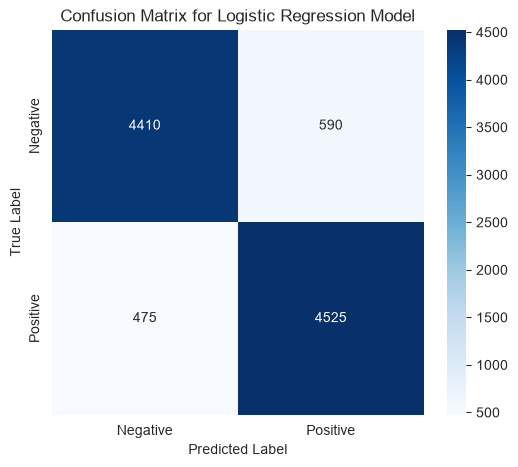

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

class_names = ['Negative', 'Positive']

plt.figure(figsize=(6, 5))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)

plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix for Logistic Regression Model')

plt.show()